#HDB Resale Price Prediction

**Dataset:** resale-flat-prices-based-on-registration-date-from-jan-2017-onwards.csv

**Objective:** To predict the resale price of a HDB flat.

##Environment Setup

In [ ]:
# Basic Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data Splitting / Cross-Validation
from sklearn.model_selection import train_test_split, KFold, cross_validate

# Preprocessing / Pipeline
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluation Metrics
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
    mean_squared_error
)



##Dataset Loading

In [ ]:
#Load data here
url = "https://raw.githubusercontent.com/muhammadmirza97/Capstone-Project-SNAIC-Week-1/main/data/resale-flat-prices-based-on-registration-date-from-jan-2017-onwards.csv"

df = pd.read_csv(url)

##Data Understanding

In [ ]:
#View the first 5 rows of the dataset
df.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979.0,61 years 04 months,232000.0
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978.0,60 years 07 months,250000.0
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980.0,62 years 05 months,262000.0
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980.0,62 years 01 month,265000.0
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980.0,62 years 05 months,265000.0


In [ ]:
#Check the number of rows and columns
print (f"Number of rows: {df.shape[0]}")
print (f"Number of columns: {df.shape[1]}")

#Check column names
print (f"Column names: {df.columns}")

#Check data types
print (df.dtypes)

Number of rows: 82801
Number of columns: 11
Column names: Index(['month', 'town', 'flat_type', 'block', 'street_name', 'storey_range',
       'floor_area_sqm', 'flat_model', 'lease_commence_date',
       'remaining_lease', 'resale_price'],
      dtype='object')
month                   object
town                    object
flat_type               object
block                   object
street_name             object
storey_range            object
floor_area_sqm         float64
flat_model              object
lease_commence_date    float64
remaining_lease         object
resale_price           float64
dtype: object


In [ ]:
#Check missing and duplicate values
print(f"Missing values:")
print(df.isna().sum())
print(f"Duplicate rows: {df.duplicated().sum()}")

Missing values:
month                   0
town                    0
flat_type               0
block                   0
street_name             0
storey_range           15
floor_area_sqm         18
flat_model              0
lease_commence_date    14
remaining_lease         0
resale_price            0
dtype: int64
Duplicate rows: 211


In [ ]:
#Show overall dataset information
display(df.info())

#Show numerical columns statistics
display(df.describe().style.format("{:,.0f}"))

#Show categorical columns statistics
display(df.describe(include="object"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82801 entries, 0 to 82800
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   month                82801 non-null  object 
 1   town                 82801 non-null  object 
 2   flat_type            82801 non-null  object 
 3   block                82801 non-null  object 
 4   street_name          82801 non-null  object 
 5   storey_range         82786 non-null  object 
 6   floor_area_sqm       82783 non-null  float64
 7   flat_model           82801 non-null  object 
 8   lease_commence_date  82787 non-null  float64
 9   remaining_lease      82801 non-null  object 
 10  resale_price         82801 non-null  float64
dtypes: float64(3), object(8)
memory usage: 6.9+ MB


None

,floor_area_sqm,lease_commence_date,resale_price
count,"82,783","82,787","82,801"
mean,98,"1,994","440,444"
std,24,13,"153,726"
min,31,"1,966","140,000"
25%,82,"1,984","330,000"
50%,95,"1,994","410,000"
75%,113,"2,003","515,000"
max,249,"2,019","1,258,000"


,month,town,flat_type,block,street_name,storey_range,flat_model,remaining_lease
count,82801,82801,82801,82801,82801,82786,82801,82801
unique,46,26,7,2457,549,17,20,625
top,2018-07,SENGKANG,4 ROOM,2,YISHUN RING RD,04 TO 06,Model A,94 years 09 months
freq,2539,6659,34288,280,1277,19268,27069,648


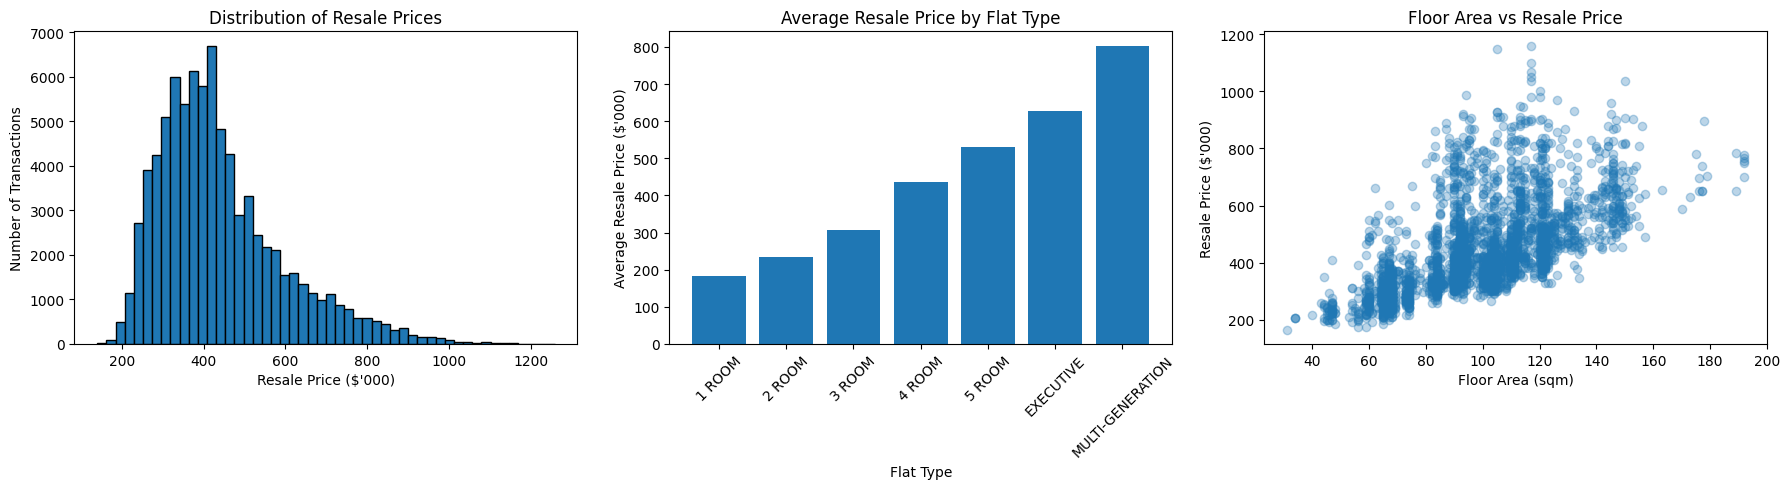

In [ ]:
# These graphs help us understand the target variable and important features.
plt.figure(figsize=(18, 5))
# Graph 1: Distribution of resale prices
plt.subplot(1, 3, 1)

plt.hist(df["resale_price"] / 1000, bins=50, edgecolor="black")

plt.title("Distribution of Resale Prices")
plt.xlabel("Resale Price ($'000)")
plt.ylabel("Number of Transactions")

# Graph 2: Average resale price by flat type
plt.subplot(1, 3, 2)

avg_price_by_flat_type = (
    df.groupby("flat_type")["resale_price"]
    .mean()
    .sort_values()
    / 1000
)

plt.bar(avg_price_by_flat_type.index, avg_price_by_flat_type.values)

plt.title("Average Resale Price by Flat Type")
plt.xlabel("Flat Type")
plt.ylabel("Average Resale Price ($'000)")
plt.xticks(rotation=45)

# Graph 3: Floor area vs resale price
plt.subplot(1, 3, 3)

# Sample is used to make the graph easier to read
df_sample = df.sample(3000, random_state=42)

plt.scatter(
    df_sample["floor_area_sqm"],
    df_sample["resale_price"] / 1000,
    alpha=0.3
)

plt.title("Floor Area vs Resale Price")
plt.xlabel("Floor Area (sqm)")
plt.ylabel("Resale Price ($'000)")


plt.tight_layout()
plt.show()

The target variable is `resale_price`.

Candidate features are all remaining columns, subject to further feature selection during modelling.

Note: `resale_price` should not be used as an input feature because it is the target value that we are trying to predict.

The dataset contains a small number of duplicate rows and missing values. As the proportion is very small compared to the total dataset size, these records will be removed during data preparation.

Columns to clean or convert:

* `month` will be converted into `sale_year`, `sale_month`, and `sale_month_index`.
* `storey_range` will be converted into `storey_mid`, which represents the midpoint of the storey range.
* `remaining_lease` will be converted into `remaining_lease_months`.
* `lease_commence_date` and `sale_year` will be used to create `flat_age`.







##Data Preparation

In [ ]:
# Create a copy of the dataset for cleaning
df_clean = df.copy()

print("Original shape:", df_clean.shape)

Original shape: (82801, 11)


In [ ]:
# Remove duplicate rows
before = df_clean.shape[0]
df_clean = df_clean.drop_duplicates()
after = df_clean.shape[0]

print("Duplicates removed:", before - after)
print("Shape:", df_clean.shape)

Duplicates removed: 211
Shape: (82590, 11)


In [ ]:
# Remove rows with missing values
before = df_clean.shape[0]
df_clean = df_clean.dropna()
after = df_clean.shape[0]

print("Rows removed:", before - after)
print("Shape:", df_clean.shape)

Rows removed: 47
Shape: (82543, 11)


In [ ]:
# Convert month column into date features
df_clean["sale_date"] = pd.to_datetime(
    df_clean["month"],
    format="%Y-%m"
)
df_clean["sale_year"] = df_clean["sale_date"].dt.year
df_clean["sale_month"] = df_clean["sale_date"].dt.month

df_clean["sale_month_index"] = (
    (df_clean["sale_year"] - df_clean["sale_year"].min()) * 12
    + df_clean["sale_month"]
)

In [ ]:
# Convert storey range into midpoint
def convert_storey(storey):
    low, high = storey.split(" TO ")
    return (int(low) + int(high)) / 2

df_clean["storey_mid"] = (
    df_clean["storey_range"]
    .apply(convert_storey)
)

In [ ]:
import re

def lease_to_months(text):
    years = 0
    months = 0
    year_match = re.search(r"(\d+)\s+years?", text)
    month_match = re.search(r"(\d+)\s+months?", text)

    if year_match:
        years = int(year_match.group(1))
    if month_match:
        months = int(month_match.group(1))
    return years * 12 + months

df_clean["remaining_lease_months"] = (
    df_clean["remaining_lease"]
    .apply(lease_to_months)
)

In [ ]:
# Create flat age feature
df_clean["flat_age"] = (
    df_clean["sale_year"]
    - df_clean["lease_commence_date"]
)

In [ ]:
print("Final shape:", df_clean.shape)
print("\nMissing values remaining:")
print(df_clean.isna().sum())

Final shape: (82543, 18)

Missing values remaining:
month                     0
town                      0
flat_type                 0
block                     0
street_name               0
storey_range              0
floor_area_sqm            0
flat_model                0
lease_commence_date       0
remaining_lease           0
resale_price              0
sale_date                 0
sale_year                 0
sale_month                0
sale_month_index          0
storey_mid                0
remaining_lease_months    0
flat_age                  0
dtype: int64


In [ ]:
df_clean.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,sale_date,sale_year,sale_month,sale_month_index,storey_mid,remaining_lease_months,flat_age
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979.0,61 years 04 months,232000.0,2017-01-01,2017,1,1,11.0,736,38.0
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978.0,60 years 07 months,250000.0,2017-01-01,2017,1,1,2.0,727,39.0
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980.0,62 years 05 months,262000.0,2017-01-01,2017,1,1,2.0,749,37.0
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980.0,62 years 01 month,265000.0,2017-01-01,2017,1,1,5.0,745,37.0
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980.0,62 years 05 months,265000.0,2017-01-01,2017,1,1,2.0,749,37.0


##Modeling

We shall be using the following techniques:
- Linear Regression
- Random Forest (Regression Tree)

In [ ]:
# X: Input columns
# y: Target column

feature_cols = ['floor_area_sqm','storey_mid', 'sale_year', 'remaining_lease_months']

X = df_clean[feature_cols]
y = df_clean['resale_price'].copy()

# print columns in X
X.columns

# First split: Train + Temp (Validation + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

# Second split: Validation + Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42
)

**Linear Regression Method**

Mean Absolute Error (MAE):  76056.49562121526
Mean Squared Error (MSE):  10496536511.260576
R-squared error:  0.5501491396224908
Root Mean Squared Error (RMSE): 102452.60617114909


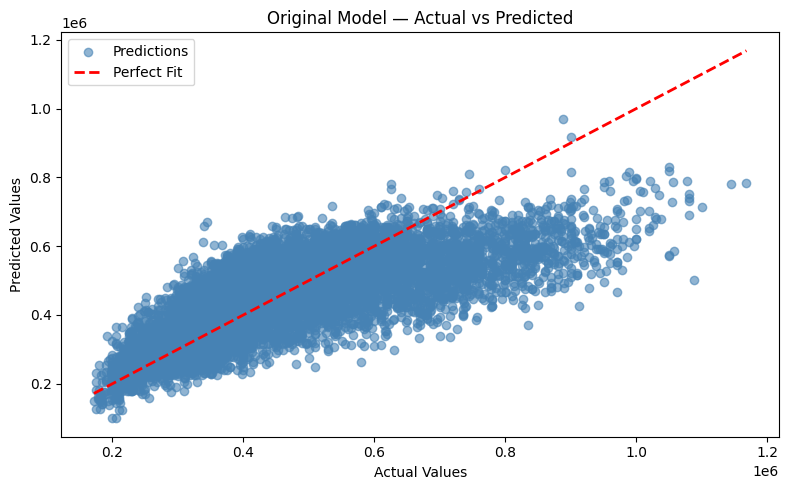

Mean Absolute Error (MAE):  76056.49562121528
Mean Squared Error (MSE):  10496536511.260572
R-squared error:  0.5501491396224909
Root Mean Squared Error (RMSE): 102452.60617114908


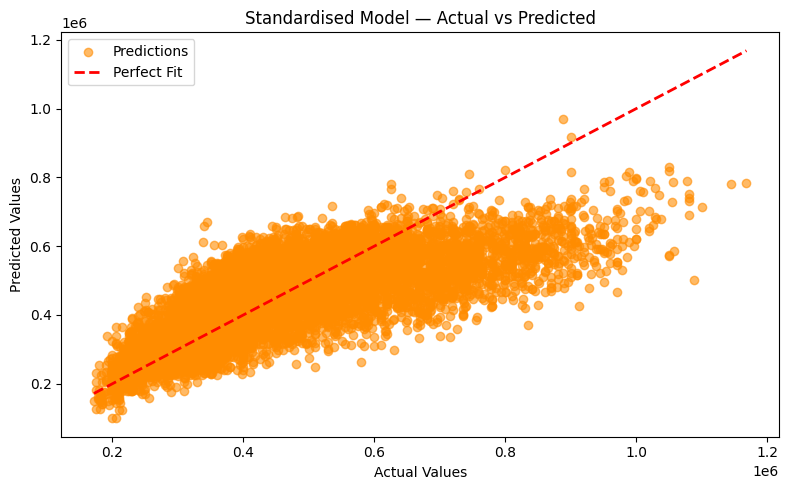

In [ ]:
regr = LinearRegression()
#fit()
regr.fit(X_train, y_train)
#predict()
prediction_result = regr.predict(X_val)

print("Mean Absolute Error (MAE): ", mean_absolute_error(y_val, prediction_result))
print("Mean Squared Error (MSE): ", mean_squared_error(y_val, prediction_result))
print("R-squared error: ", r2_score(y_val, prediction_result))
print("Root Mean Squared Error (RMSE):", root_mean_squared_error(y_val, prediction_result))

# Draw the graph
plt.figure(figsize=(8, 5))
plt.scatter(y_val, prediction_result, alpha=0.6, color='steelblue', label='Predictions')
plt.plot([y_val.min(), y_val.max()],
         [y_val.min(), y_val.max()],
         'r--', linewidth=2, label='Perfect Fit')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Original Model — Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

# Standardise the data

# Initialize the StandardScaler object
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

standardised_regr = LinearRegression()
#fit()
standardised_regr.fit(X_train_scaled, y_train)
#predict()
norm_prediction_result = standardised_regr.predict(X_val_scaled)

print("Mean Absolute Error (MAE): ", mean_absolute_error(y_val, norm_prediction_result))
print("Mean Squared Error (MSE): ", mean_squared_error(y_val, norm_prediction_result))
print("R-squared error: ", r2_score(y_val, norm_prediction_result))
print("Root Mean Squared Error (RMSE):", root_mean_squared_error(y_val, norm_prediction_result))

# Draw the graph
plt.figure(figsize=(8, 5))
plt.scatter(y_val, norm_prediction_result, alpha=0.6, color='darkorange', label='Predictions')
plt.plot([y_val.min(), y_val.max()],
         [y_val.min(), y_val.max()],
         'r--', linewidth=2, label='Perfect Fit')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Standardised Model — Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

**Random Forest Method**

Here we will test the impact the various hyperparameters of Random Forest Regressor has on its predicted values, through the use of error metrics (r squared and mean absolute error).

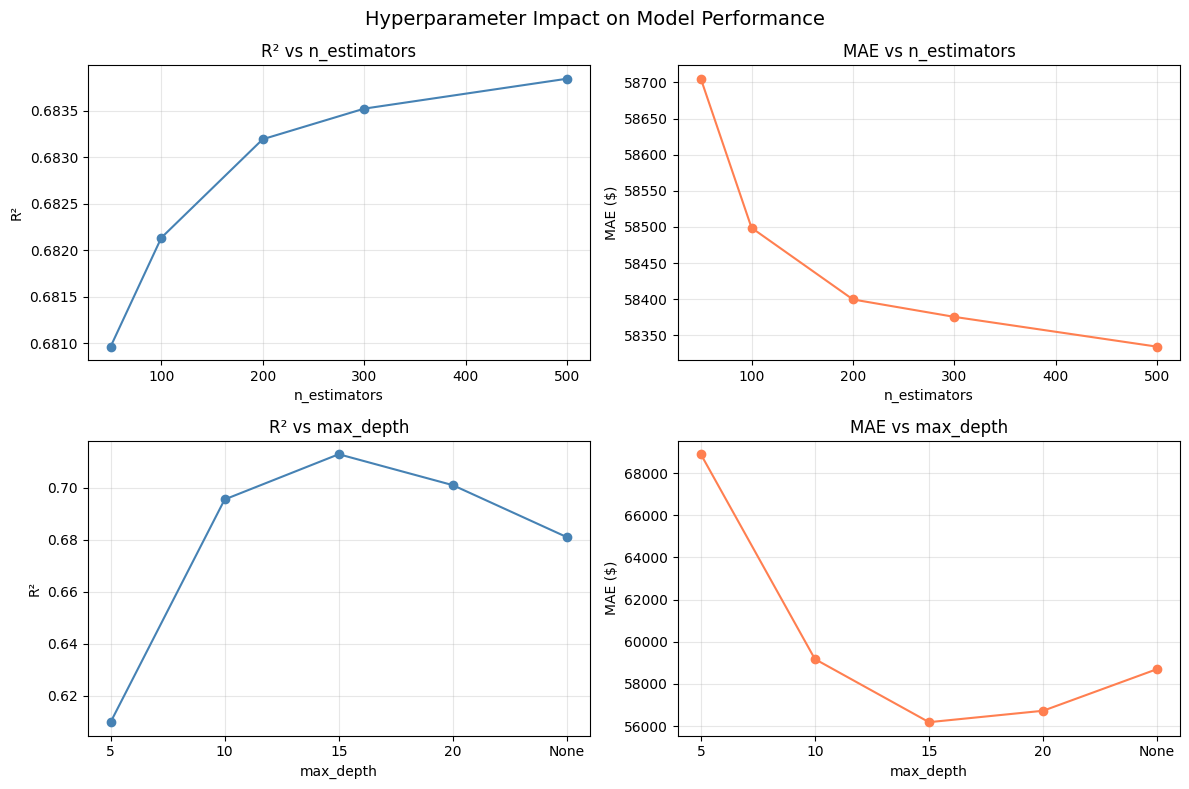

Best n_estimators: 200
Best max_depth: 15


RandomForestRegressor(max_depth=15, n_estimators=200, n_jobs=-1,
                      random_state=42)

In [ ]:
# Various hyperparameters for random forest regressor
n_estimators_values = [50, 100, 200, 300, 500]
max_depth_values = [5, 10, 15, 20, None]

# Plot 1: n_estimators (fix max_depth=None)
r2_ne, mae_ne = [], []
#print("^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^")
for n in n_estimators_values:
    m = RandomForestRegressor(n_estimators=n, max_depth=None, random_state=42, n_jobs=-1)
    m.fit(X_train, y_train)
    y_pred = m.predict(X_val)
    r2_ne.append(r2_score(y_val, y_pred))
    mae_ne.append(mean_absolute_error(y_val, y_pred))
    #print(f"Mean Absolute Error (n_estimator:{n}): {mean_absolute_error(y_pred, y_test)}")
    #print(f"Mean Squared Error (n_estimator:{n}): ", mean_squared_error(y_pred, y_test))
    #print(f"R-squared error (n_estimator:{n}): ", r2_score(y_pred, y_test))
    #print(f"Root Mean Squared Error (n_estimator:{n}): ", root_mean_squared_error(y_pred, y_test))
    #print(f"Mean Absolute Percentage Error (n_estimator:{n}): ", mean_absolute_percentage_error(y_pred, y_test))
#print("vvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvv")

# Plot 2: max_depth (fix n_estimators=50)
r2_md, mae_md = [], []
#print("^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^")
for d in max_depth_values:
    m = RandomForestRegressor(n_estimators=50, max_depth=d, random_state=42, n_jobs=-1)
    m.fit(X_train, y_train)
    y_pred = m.predict(X_val)
    r2_md.append(r2_score(y_val, y_pred))
    mae_md.append(mean_absolute_error(y_val, y_pred))
    #print(f"Mean Absolute Error (max_depth:{d}): {mean_absolute_error(y_pred, y_test)}")
    #print(f"Mean Squared Error (max_depth:{d}): {mean_squared_error(y_pred, y_test)}")
    #print(f"R-squared error (max_depth:{d}): {r2_score(y_pred, y_test)}")
    #print(f"Root Mean Squared Error (max_depth:{d}): {root_mean_squared_error(y_pred, y_test)}")
    #print(f"Mean Absolute Percentage Error (max_depth:{d}): {mean_absolute_percentage_error(y_pred, y_test)}")
#print("vvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvvv")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Hyperparameter Impact on Model Performance', fontsize=14)

x_labels_depth = [str(d) if d else 'None' for d in max_depth_values]

# R² vs n_estimators
axes[0, 0].plot(n_estimators_values, r2_ne, marker='o', color='steelblue')
axes[0, 0].set_title('R² vs n_estimators')
axes[0, 0].set_xlabel('n_estimators'); axes[0, 0].set_ylabel('R²')
axes[0, 0].grid(True, alpha=0.3)

# MAE vs n_estimators
axes[0, 1].plot(n_estimators_values, mae_ne, marker='o', color='coral')
axes[0, 1].set_title('MAE vs n_estimators')
axes[0, 1].set_xlabel('n_estimators'); axes[0, 1].set_ylabel('MAE ($)')
axes[0, 1].grid(True, alpha=0.3)

# R² vs max_depth
axes[1, 0].plot(x_labels_depth, r2_md, marker='o', color='steelblue')
axes[1, 0].set_title('R² vs max_depth')
axes[1, 0].set_xlabel('max_depth'); axes[1, 0].set_ylabel('R²')
axes[1, 0].grid(True, alpha=0.3)

# MAE vs max_depth
axes[1, 1].plot(x_labels_depth, mae_md, marker='o', color='coral')
axes[1, 1].set_title('MAE vs max_depth')
axes[1, 1].set_xlabel('max_depth'); axes[1, 1].set_ylabel('MAE ($)')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Optimal hyperparameters
threshold = 0.001  # minimum R² improvement worth caring about
gains = np.diff(r2_ne)  # difference between consecutive R² values
# find first index where gain drops below threshold
sweet_spot_idx = next(i for i, g in enumerate(gains) if g < threshold)
best_n_estimators = n_estimators_values[sweet_spot_idx]

best_max_depth = max_depth_values[np.argmax(r2_md)]

print("Best n_estimators: %d" % best_n_estimators)
print("Best max_depth: %s" % str(best_max_depth))  # %s because None is not an integer

# Best model
best_random_forest = RandomForestRegressor(n_estimators=best_n_estimators, max_depth=best_max_depth, random_state=42, n_jobs=-1)
best_random_forest.fit(X_train, y_train)


## Evaluation

Evaluation is the stage in CRISP-DM where the trained model is assessed to determine how well it meets the project objective. In this project, the objective is to predict HDB resale prices using the available resale flat features.

The final model used for this project is a Random Forest Regressor. The model is evaluated by comparing its predicted resale prices against the actual resale prices.

To avoid test set leakage, the test set is only used after the model selection and tuning process is completed. Model tuning and comparison are done using the training and validation data, while the test set is reserved for the final evaluation.

### Evaluation Metrics

The following metrics are used:

- **MAE (Mean Absolute Error)** measures the average absolute difference between the actual and predicted resale prices. It is easy to interpret because it is in dollars.
- **RMSE (Root Mean Squared Error)** also measures prediction error in dollars, but gives a larger penalty to large mistakes.
- **R² Score** measures how much of the variation in resale prices is explained by the model. A higher R² score means the model explains the resale price pattern better.
- **MAPE (Mean Absolute Percentage Error)** measures the prediction error as a percentage, making it easier to understand the model’s relative error.

In [ ]:
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2 Score": r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred)
    }

### Cross-validation Results

Five-fold cross-validation was performed using the training data only. This was done to compare the baseline Linear Regression model against the Random Forest Regressor before final testing.

The test set was not used during cross-validation, which helps avoid test set leakage.



In [ ]:
# Cross-validation on training data only
# best_n_estimators = 200
# best_max_depth = 15

cv = KFold(n_splits=5, shuffle=True, random_state=42)

lr_model_cv = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

rf_model_cv = RandomForestRegressor(
    n_estimators=best_n_estimators,
    max_depth=best_max_depth,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "MAPE": "neg_mean_absolute_percentage_error"
}

lr_cv_scores = cross_validate(
    lr_model_cv,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

rf_cv_scores = cross_validate(
    rf_model_cv,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

cv_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "CV MAE": -lr_cv_scores["test_MAE"].mean(),
        "CV RMSE": -lr_cv_scores["test_RMSE"].mean(),
        "CV R2": lr_cv_scores["test_R2"].mean(),
        "CV MAPE": -lr_cv_scores["test_MAPE"].mean()
    },
    {
        "Model": "Random Forest Regressor",
        "CV MAE": -rf_cv_scores["test_MAE"].mean(),
        "CV RMSE": -rf_cv_scores["test_RMSE"].mean(),
        "CV R2": rf_cv_scores["test_R2"].mean(),
        "CV MAPE": -rf_cv_scores["test_MAPE"].mean()
    }
])

cv_results

,Model,CV MAE,CV RMSE,CV R2,CV MAPE
0,Linear Regression,77309.575841,103996.058311,0.543377,0.170936
1,Random Forest Regressor,57402.985741,83185.736482,0.707839,0.127056


### Final Test Set Evaluation

After Random Forest was selected based on the cross-validation and validation results, the final model was evaluated once on the unseen test set.

This provides a fair estimate of how the selected model may perform on new HDB resale flat records.

In [ ]:
# Final test set evaluation

X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

final_rf_model = RandomForestRegressor(
    n_estimators=best_n_estimators,
    max_depth=best_max_depth,
    random_state=42,
    n_jobs=-1
)

final_rf_model.fit(X_train_final, y_train_final)

# Test set is used only once here
rf_test_pred = final_rf_model.predict(X_test)

test_results = pd.DataFrame([
    evaluate_model("Final Random Forest - Test", y_test, rf_test_pred)
])

test_results

,Model,MAE,RMSE,R2 Score,MAPE
0,Final Random Forest - Test,56431.242153,82397.978411,0.716861,0.1245


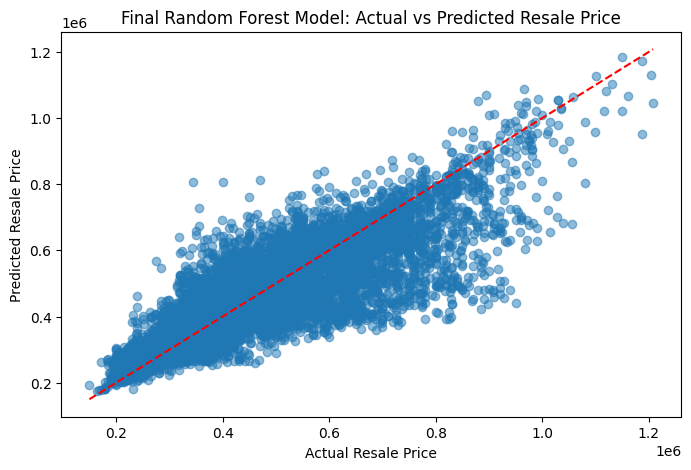

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_test_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Resale Price")
plt.ylabel("Predicted Resale Price")
plt.title("Final Random Forest Model: Actual vs Predicted Resale Price")

plt.show()

### Failure Analysis

Failure analysis was conducted after the final Random Forest model was evaluated on the test set. The purpose is to inspect where the model made the largest prediction errors, instead of only relying on aggregate metrics such as MAE, RMSE and R².

The model was trained using only numerical features: `floor_area_sqm`, `storey_mid`, `sale_year`, and `remaining_lease_months`.

Although `town` and `flat_type` were not used as model inputs, they were added back after prediction for interpretation. This helps identify whether the largest errors are linked to missing categorical or location-based information.

In [ ]:
# Failure analysis

error_analysis = X_test.copy()

error_analysis["Actual Price"] = y_test.values
error_analysis["Predicted Price"] = rf_test_pred
error_analysis["Prediction Error"] = error_analysis["Predicted Price"] - error_analysis["Actual Price"]
error_analysis["Absolute Error"] = abs(error_analysis["Prediction Error"])
error_analysis["Percentage Error"] = error_analysis["Absolute Error"] / error_analysis["Actual Price"]

# Pull original columns back for richer failure analysis
error_analysis_rich = error_analysis.copy()
error_analysis_rich['town'] = df_clean.loc[X_test.index, 'town']
error_analysis_rich['flat_type'] = df_clean.loc[X_test.index, 'flat_type']

# Average error by flat type
print(error_analysis_rich.groupby('flat_type')['Absolute Error'].mean().sort_values(ascending=False),'\n')

# Average error by town (top 10 worst)
print(error_analysis_rich.groupby('town')['Absolute Error'].mean().sort_values(ascending=False).head(10), '\n')

flat_type
EXECUTIVE           74445.814989
5 ROOM              72406.781923
4 ROOM              59587.511170
MULTI-GENERATION    50534.052164
3 ROOM              32696.112799
2 ROOM              15280.327123
1 ROOM              12405.552218
Name: Absolute Error, dtype: float64 

town
BUKIT TIMAH        237866.009438
BISHAN             137518.822883
BUKIT MERAH        112091.427860
CENTRAL AREA       105484.321934
QUEENSTOWN          97373.199956
KALLANG/WHAMPOA     78514.880715
SERANGOON           76806.211007
MARINE PARADE       76493.243193
CHOA CHU KANG       72979.581168
GEYLANG             69772.153747
Name: Absolute Error, dtype: float64 



In [ ]:
worst_20 = (
    error_analysis_rich
    .sort_values("Absolute Error", ascending=False)
    .head(20)
)

print("=== Top 20 worst predictions ===")
display(
    worst_20[[
        "town", "flat_type", "floor_area_sqm", "storey_mid",
        "remaining_lease_months", "Actual Price", "Predicted Price",
        "Prediction Error", "Absolute Error"
    ]].reset_index(drop=True)
)

# Compare worst-20 feature averages against the overall test set
print("\n=== Feature means: worst-20 vs full test set ===")
comparison_cols = ["floor_area_sqm", "storey_mid", "remaining_lease_months"]
comparison_df = pd.DataFrame({
    "Worst 20": worst_20[comparison_cols].mean(),
    "All test rows": error_analysis_rich[comparison_cols].mean()
}).round(1)
display(comparison_df)

# Over- vs under-prediction in the worst cases
over  = (worst_20["Prediction Error"] > 0).sum()
under = (worst_20["Prediction Error"] < 0).sum()
print(f"\nOverpredictions (model > actual): {over}")
print(f"Underpredictions (model < actual): {under}")

=== Top 20 worst predictions ===


,town,flat_type,floor_area_sqm,storey_mid,remaining_lease_months,Actual Price,Predicted Price,Prediction Error,Absolute Error
0,CENTRAL AREA,4 ROOM,94.0,17.0,1074,950000.0,440661.121270,-509338.878730,509338.878730
1,GEYLANG,5 ROOM,111.0,8.0,958,928000.0,457420.708595,-470579.291405,470579.291405
2,BUKIT MERAH,5 ROOM,110.0,17.0,1007,885000.0,421287.329536,-463712.670464,463712.670464
3,WOODLANDS,5 ROOM,126.0,20.0,683,345000.0,806063.380485,461063.380485,461063.380485
4,BUKIT MERAH,4 ROOM,92.0,17.0,1139,940000.0,479084.239388,-460915.760612,460915.760612
5,BUKIT MERAH,5 ROOM,110.0,14.0,989,898000.0,438109.161806,-459890.838194,459890.838194
6,BUKIT MERAH,5 ROOM,110.0,11.0,977,910000.0,458583.712624,-451416.287376,451416.287376
7,BUKIT MERAH,5 ROOM,110.0,14.0,999,920000.0,469116.519734,-450883.480266,450883.480266
8,GEYLANG,5 ROOM,110.0,11.0,968,890000.0,453855.082853,-436144.917147,436144.917147
9,BUKIT MERAH,5 ROOM,115.0,5.0,1011,920000.0,484774.415698,-435225.584302,435225.584302



=== Feature means: worst-20 vs full test set ===


,Worst 20,All test rows
floor_area_sqm,107.3,97.3
storey_mid,12.0,8.6
remaining_lease_months,1000.1,895.3



Overpredictions (model > actual): 1
Underpredictions (model < actual): 19


### Failure Analysis Interpretation

The grouped error results show that the model has higher average absolute errors for larger flat types. **EXECUTIVE** flats have the highest average error at about **\$74,430**, followed by **5 ROOM** flats at about **\$73,001** and **4 ROOM** flats at about **\$59,977**.

The town-level results also show that errors are larger in certain high-demand or premium locations. **BUKIT TIMAH** has the highest average absolute error at about **\$235,840**, followed by **BISHAN** at about **\$137,484**, **BUKIT MERAH** at about **\$114,060**, and **CENTRAL AREA** at about **\$105,274**.

Since `town` and `flat_type` were not used as model inputs, these results suggest that the current numerical feature set may be missing important categorical and location-based effects. In other words, the model can learn from floor area, storey level, sale year and remaining lease, but it cannot fully account for price differences caused by town popularity, flat type, nearby amenities, MRT access, schools, and buyer demand.

Overall, the failure analysis shows that the Random Forest model performs reasonably with the current features, but larger errors occur in premium towns and larger flat types. Future improvements should include encoded `town` and `flat_type` features to better capture these effects.

In [ ]:
error_summary = error_analysis[["Absolute Error", "Percentage Error"]].describe()
error_summary

,Absolute Error,Percentage Error
count,12382.000000,1.238200e+04
mean,56431.242153,1.245000e-01
std,60043.591853,1.097318e-01
min,0.204593,6.373624e-07
25%,17443.766362,4.418947e-02
50%,38273.527631,9.495133e-02
75%,72628.975523,1.757906e-01
max,509338.878730,1.336416e+00


### Error Summary

The error summary shows the overall spread of prediction errors on the test set. Across 12,382 test records, the model has an average absolute error of about **\$56,807** and a median absolute error of about **\$38,651**.

The average percentage error is about **12.53%**, while the median percentage error is about **9.55%**. This means that a typical prediction is usually within around 10% of the actual resale price, although some cases have much larger errors.

The maximum absolute error is about **\$517,859**, showing that the model still struggles with some unusual resale flat records. These large-error cases were further examined in the failure analysis.

### Business Recommendation

The model can be used as a supporting tool to estimate HDB resale prices, but it should not be treated as a definitive valuation.

Prediction errors affect buyers and sellers differently:

| Error type | Who is harmed | Impact |
|---|---|---|
| Overprediction | Buyer | Buyer may overpay because the predicted price is higher than the actual market value |
| Underprediction | Seller | Seller may price the flat too low and lose potential value |

For buyer-facing use, a conservative safety margin can be applied by subtracting one test MAE from the predicted price. Based on the final test result, this is approximately **\$57,000**.

```python
displayed_estimate = predicted_price - test_MAE